In [150]:
!pip install -q fairlearn==0.15.0

import sys, sklearn, pandas as pd, numpy as np, matplotlib, matplotlib.pyplot as plt, fairlearn
print("Python    :", sys.version.split()[0])
for lib in (sklearn, pd, np, matplotlib, fairlearn):
    print(f"{lib.__name__:<10}:", lib.__version__)

Python    : 3.13.18
sklearn   : 1.6.1
pandas    : 2.3.3
numpy     : 2.1.3
matplotlib: 3.10.0
fairlearn : 0.15.0


In [151]:
URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
raw = pd.read_csv(URL)
print(raw.shape)   # attendu : (7214, 53)
raw.head()

(7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [152]:
cols = ["age", "age_cat", "sex", "race", "c_charge_degree", "priors_count",
        "juv_fel_count", "juv_misd_count", "juv_other_count",
        "days_b_screening_arrest", "decile_score", "score_text",
        "is_recid", "two_year_recid"]

df = raw[cols].copy()
df = df[(df["days_b_screening_arrest"].between(-30, 30)) &
        (df["is_recid"] != -1) &
        (df["c_charge_degree"] != "O") &
        (df["score_text"] != "N/A")]

print("Lignes après filtrage :", len(df))
print("Valeurs manquantes :\n", df.isna().sum()[df.isna().sum() > 0])

Lignes après filtrage : 6172
Valeurs manquantes :
 Series([], dtype: int64)


In [153]:
for col in ["race", "sex", "age_cat"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().to_frame("effectif")
            .assign(pourcentage=lambda t: (100 * t["effectif"] / len(df)).round(1)))


--- race ---
                  effectif  pourcentage
race                                   
African-American      3175         51.4
Caucasian             2103         34.1
Hispanic               509          8.2
Other                  343          5.6
Asian                   31          0.5
Native American         11          0.2

--- sex ---
        effectif  pourcentage
sex                          
Male        4997         81.0
Female      1175         19.0

--- age_cat ---
                 effectif  pourcentage
age_cat                               
25 - 45              3532         57.2
Less than 25         1347         21.8
Greater than 45      1293         20.9


In [154]:
print("Taux de récidive global :", round(df["two_year_recid"].mean(), 3))
print("\nPar origine :")
print(df.groupby("race")["two_year_recid"].agg(["count", "mean"]).round(3))
print("\nPar sexe :")
print(df.groupby("sex")["two_year_recid"].agg(["count", "mean"]).round(3))

Taux de récidive global : 0.455

Par origine :
                  count   mean
race                          
African-American   3175  0.523
Asian                31  0.258
Caucasian          2103  0.391
Hispanic            509  0.371
Native American      11  0.455
Other               343  0.362

Par sexe :
        count   mean
sex                 
Female   1175  0.351
Male     4997  0.479


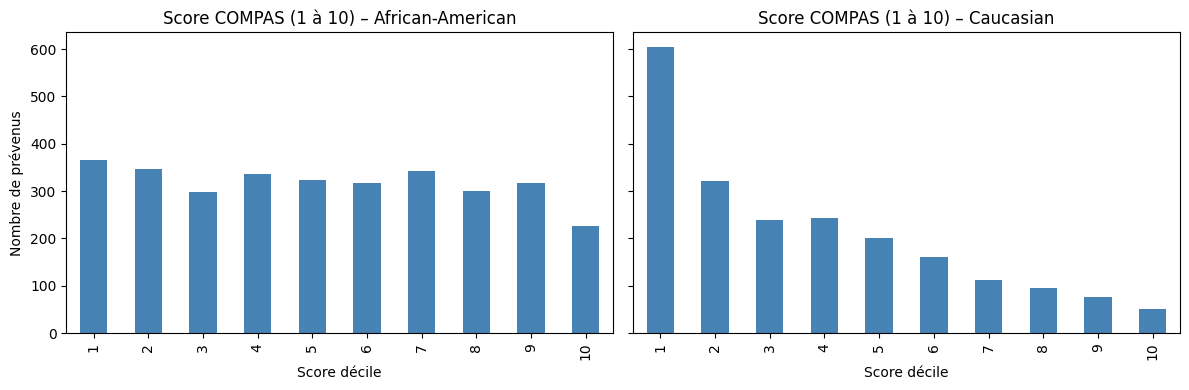

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, groupe in zip(axes, ["African-American", "Caucasian"]):
    (df[df["race"] == groupe]["decile_score"]
       .value_counts().sort_index()
       .plot(kind="bar", ax=ax, color="steelblue"))
    ax.set_title(f"Score COMPAS (1 à 10) – {groupe}")
    ax.set_xlabel("Score décile")
axes[0].set_ylabel("Nombre de prévenus")
plt.tight_layout()
plt.show()

In [156]:
print(df.groupby("race")["priors_count"].describe().round(2))

                   count  mean   std  min  25%  50%  75%   max
race                                                          
African-American  3175.0  4.24  5.44  0.0  0.0  2.0  6.0  38.0
Asian               31.0  1.35  2.24  0.0  0.0  0.0  2.0   9.0
Caucasian         2103.0  2.29  3.57  0.0  0.0  1.0  3.0  36.0
Hispanic           509.0  2.10  3.70  0.0  0.0  1.0  2.0  26.0
Native American     11.0  5.18  7.11  0.0  0.5  2.0  6.0  22.0
Other              343.0  1.75  3.41  0.0  0.0  0.0  2.0  31.0


## 1. Analyse exploratoire : synthèse

- Après les filtres de ProPublica, il reste **6 172 prévenus** (comté de Broward, Floride, 2013-2014).
- L'audit porte sur les **Afro-Américains (51,4 %)** et les **Caucasiens (34,1 %)** : les autres groupes
  sont trop petits pour des statistiques fiables (11 personnes pour « Native American »).
- **Les taux de base diffèrent** : 52,3 % de récidive mesurée chez les Afro-Américains contre 39,1 %
  chez les Caucasiens. Cet écart aura une conséquence directe sur les métriques d'équité (section 6).
- **Attention à la cible** : `two_year_recid` mesure une *nouvelle arrestation*, pas un nouveau délit.
  Si un groupe est plus surveillé par la police, son taux mesuré est mécaniquement plus élevé.
  Le biais peut donc se trouver dans l'étiquette elle-même.
- **Variable proxy** : le nombre d'antécédents (`priors_count`) est presque deux fois plus élevé en moyenne
  chez les Afro-Américains (4,24 contre 2,29). Retirer la race des variables ne suffira donc pas à
  rendre le modèle neutre : l'information passe par les variables corrélées.
  - **Distribution des scores COMPAS** : uniforme de 1 à 9 chez les Afro-Américains, fortement concentrée
  sur les scores bas chez les Caucasiens. Cette différence ne suffit pas à conclure à un biais, puisque
  les taux de base diffèrent aussi : il faut confronter les scores aux récidives observées (section 2).

In [157]:
df_ab = df[df["race"].isin(["African-American", "Caucasian"])].copy()
df_ab["compas_haut_risque"] = (df_ab["decile_score"] >= 5).astype(int)

print("Effectifs :", df_ab["race"].value_counts().to_dict())
pd.crosstab(df_ab["race"], df_ab["score_text"])

Effectifs : {'African-American': 3175, 'Caucasian': 2103}


score_text,High,Low,Medium
race,,,
African-American,845,1346,984
Caucasian,223,1407,473


In [158]:
from sklearn.metrics import confusion_matrix

for groupe, d in df_ab.groupby("race"):
    vn, fp, fn, vp = confusion_matrix(d["two_year_recid"], d["compas_haut_risque"]).ravel()
    print(f"\n=== {groupe} (n={len(d)}) ===")
    print(f"VP={vp}  FP={fp}  FN={fn}  VN={vn}")
    print(f"FPR       = {fp / (fp + vn):.3f}")
    print(f"FNR       = {fn / (fn + vp):.3f}")
    print(f"Précision = {vp / (vp + fp):.3f}")


=== African-American (n=3175) ===
VP=1188  FP=641  FN=473  VN=873
FPR       = 0.423
FNR       = 0.285
Précision = 0.650

=== Caucasian (n=2103) ===
VP=414  FP=282  FN=408  VN=999
FPR       = 0.220
FNR       = 0.496
Précision = 0.595


In [159]:
from fairlearn.metrics import (MetricFrame, false_positive_rate, false_negative_rate,
                               selection_rate)
from sklearn.metrics import accuracy_score, precision_score

metriques = {
    "exactitude": accuracy_score,
    "précision": precision_score,
    "FPR": false_positive_rate,
    "FNR": false_negative_rate,
    "taux_sélection": selection_rate,
}

mf_compas = MetricFrame(metrics=metriques,
                        y_true=df_ab["two_year_recid"],
                        y_pred=df_ab["compas_haut_risque"],
                        sensitive_features=df_ab["race"])

print("Global :\n", mf_compas.overall.round(3))
print("\nPar groupe :\n", mf_compas.by_group.round(3))
print("\nÉcart max entre groupes :\n", mf_compas.difference().round(3))

Global :
 exactitude        0.658
précision         0.634
FPR               0.330
FNR               0.355
taux_sélection    0.478
dtype: float64

Par groupe :
                   exactitude  précision    FPR    FNR  taux_sélection
race                                                                 
African-American       0.649      0.650  0.423  0.285           0.576
Caucasian              0.672      0.595  0.220  0.496           0.331

Écart max entre groupes :
 exactitude        0.023
précision         0.055
FPR               0.203
FNR               0.212
taux_sélection    0.245
dtype: float64


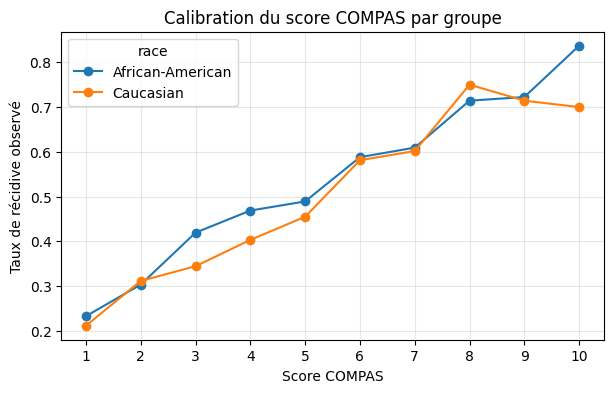

In [160]:
calib = (df_ab.groupby(["decile_score", "race"])["two_year_recid"]
              .mean().unstack())

ax = calib.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("Score COMPAS")
ax.set_ylabel("Taux de récidive observé")
ax.set_title("Calibration du score COMPAS par groupe")
ax.set_xticks(range(1, 11))
ax.grid(alpha=0.3)
plt.show()

## 2. Audit du score COMPAS : synthèse

Seuil retenu (comme ProPublica) : score ≥ 5 = « haut risque ».

| Métrique | Afro-Américains | Caucasiens |
|---|---|---|
| Exactitude | 64,9 % | 67,2 % |
| Taux de faux positifs | 42,3 % | 22,0 % |
| Taux de faux négatifs | 28,5 % | 49,6 % |
| Précision | 65,0 % | 59,5 % |
| Part classée « haut risque » | 57,6 % | 33,1 % |

- **Constat de ProPublica reproduit** : parmi les personnes non réarrêtées, les Afro-Américains ont presque
  deux fois plus souvent été classés « haut risque » (42,3 % contre 22,0 %). Les erreurs inverses
  (récidivistes classés « faible risque ») touchent surtout les Caucasiens (49,6 % contre 28,5 %).
- **Argument de Northpointe vérifié** : à score égal, les taux de récidive observés sont proches entre les
  groupes (calibration), et la précision est comparable.
- **Les deux constats sont vrais en même temps** : avec des taux de base différents, un outil calibré ne peut
  pas avoir des taux d'erreur égaux (voir section 6).
- L'exactitude globale, presque identique, masque entièrement ces écarts.

In [161]:
from sklearn.model_selection import train_test_split

num = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
cat = ["sex", "c_charge_degree"]

X = df_ab[num + cat]
y = df_ab["two_year_recid"]
A = df_ab["race"]                 
strate = y.astype(str) + "_" + A 

(X_train, X_test, y_train, y_test,
 A_train, A_test, compas_train, compas_test) = train_test_split(
    X, y, A, df_ab["decile_score"],
    test_size=0.3, random_state=42, stratify=strate)

print("Train :", X_train.shape, " Test :", X_test.shape)
print("\nTaux de récidive par groupe (test) :")
print(y_test.groupby(A_test).mean().round(3))

Train : (3694, 7)  Test : (1584, 7)

Taux de récidive par groupe (test) :
race
African-American    0.524
Caucasian           0.391
Name: two_year_recid, dtype: float64


In [162]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone

prepro = ColumnTransformer([
    ("num", StandardScaler(), num),
    ("cat", OneHotEncoder(drop="if_binary", sparse_output=False), cat),
])

logreg = Pipeline([("prep", prepro),
                   ("clf", LogisticRegression(max_iter=1000))])
hgb = Pipeline([("prep", clone(prepro)),
                ("clf", HistGradientBoostingClassifier(max_depth=3, random_state=42))])

logreg.fit(X_train, y_train)
hgb.fit(X_train, y_train)

p_logreg = logreg.predict_proba(X_test)[:, 1]
p_hgb    = hgb.predict_proba(X_test)[:, 1]

In [163]:
from sklearn.metrics import roc_auc_score, accuracy_score

def evaluer(nom, score, seuil=0.5):
    pred = (score >= seuil).astype(int)
    return {"modèle": nom,
            "AUC": roc_auc_score(y_test, score),
            "exactitude": accuracy_score(y_test, pred)}


resultats = pd.DataFrame([
    evaluer("COMPAS (score ≥ 5)", compas_test / 10),
    evaluer("Régression logistique", p_logreg),
    evaluer("Gradient boosting", p_hgb),
]).set_index("modèle").round(3)
resultats

,AUC,exactitude
modèle,,
COMPAS (score ≥ 5),0.704,0.662
Régression logistique,0.719,0.679
Gradient boosting,0.717,0.666


In [164]:
noms = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["clf"].coef_[0], index=noms).sort_values()
print(coefs.round(3))

num__age                 -0.548
cat__c_charge_degree_M   -0.191
num__juv_misd_count      -0.055
num__juv_fel_count        0.041
num__juv_other_count      0.140
cat__sex_Male             0.247
num__priors_count         0.817
dtype: float64


## 3. Modèles : synthèse

Variables utilisées : âge, sexe, nombre d'antécédents, antécédents juvéniles (3 types), gravité de
l'accusation. Variables écartées : la race (gardée à part pour l'audit), le score COMPAS, et `is_recid`
(fuite de données). Découpage 70/30, stratifié par cible et par groupe.

| Modèle | AUC | Exactitude |
|---|---|---|
| COMPAS (score ≥ 5) | 0,704 | 66,2 % |
| Régression logistique | 0,719 | 67,9 % |
| Gradient boosting | 0,717 | 66,6 % |

- Un modèle linéaire à 7 variables obtient des performances **comparables** à COMPAS, légèrement
  supérieures en moyenne (AUC 0,727 ± 0,008 contre 0,713 ± 0,010 sur 10 découpages ; meilleur dans
  7 cas sur 10). Le boosting n'apporte rien : on retient la régression logistique, plus transparente.
- Variable la plus influente : le **nombre d'antécédents**, qui est aussi un **proxy** de la race
  (section 1). Retirer la race des variables ne garantit donc pas un modèle équitable.

In [165]:
from fairlearn.metrics import (demographic_parity_difference,
                               demographic_parity_ratio,
                               equalized_odds_difference)

preds = {
    "COMPAS (score ≥ 5)":    (compas_test >= 5).astype(int).to_numpy(),
    "Régression logistique": (p_logreg >= 0.5).astype(int),
    "Gradient boosting":     (p_hgb >= 0.5).astype(int),
}

mfs, lignes = {}, []
for nom, pred in preds.items():
    mf = MetricFrame(metrics=metriques, y_true=y_test, y_pred=pred,
                     sensitive_features=A_test)
    mfs[nom] = mf
    lignes.append({
        "modèle": nom,
        "exactitude": mf.overall["exactitude"],
        "écart parité dém.": demographic_parity_difference(y_test, pred, sensitive_features=A_test),
        "ratio parité dém.": demographic_parity_ratio(y_test, pred, sensitive_features=A_test),
        "écart equalized odds": equalized_odds_difference(y_test, pred, sensitive_features=A_test),
    })

synthese = pd.DataFrame(lignes).set_index("modèle").round(3)
synthese

,exactitude,écart parité dém.,ratio parité dém.,écart equalized odds
modèle,,,,
COMPAS (score ≥ 5),0.662,0.245,0.576,0.211
Régression logistique,0.679,0.259,0.473,0.244
Gradient boosting,0.666,0.231,0.534,0.228


In [166]:
par_groupe = pd.concat({nom: mf.by_group for nom, mf in mfs.items()},
                       names=["modèle"]).round(3)
par_groupe

exactitude  précision    FPR    FNR  \
modèle                race                                                    
COMPAS (score ≥ 5)    African-American       0.654      0.653  0.421  0.279   
                      Caucasian              0.675      0.600  0.219  0.490   
Régression logistique African-American       0.668      0.695  0.315  0.347   
                      Caucasian              0.696      0.687  0.120  0.591   
Gradient boosting     African-American       0.661      0.686  0.326  0.351   
                      Caucasian              0.674      0.623  0.164  0.579   

                                        taux_sélection  
modèle                race                              
COMPAS (score ≥ 5)    African-American           0.578  
                      Caucasian                  0.333  
Régression logistique African-American           0.492  
                      Caucasian                  0.233  
Gradient boosting     African-American           0.495  
                      Caucasian                  0.265

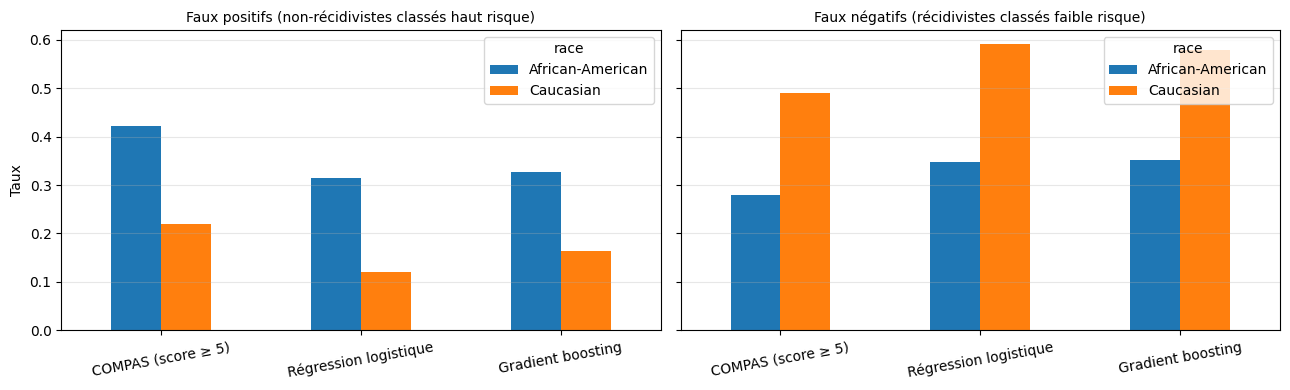

In [167]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, m, titre in zip(axes, ["FPR", "FNR"],
                        ["Faux positifs (non-récidivistes classés haut risque)",
                         "Faux négatifs (récidivistes classés faible risque)"]):
    par_groupe[m].unstack().plot(kind="bar", ax=ax, rot=10)
    ax.set_title(titre, fontsize=10)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Taux")
plt.tight_layout()
plt.show()

## 4. Équité de notre modèle : synthèse

| Modèle | Exactitude | Écart parité dém. | Ratio parité dém. | Écart equalized odds |
|---|---|---|---|---|
| COMPAS (score ≥ 5) | 66,2 % | 0,245 | 0,576 | 0,211 |
| Régression logistique | 67,9 % | 0,259 | 0,473 | 0,244 |
| Gradient boosting | 66,6 % | 0,231 | 0,534 | 0,228 |

- **L'équité par ignorance échoue** : sans voir la race, le modèle n'est pas plus équitable que COMPAS.
  Il réduit l'écart de faux positifs (0,149 contre 0,198 en moyenne sur 10 découpages) mais creuse
  celui des faux négatifs (0,259 contre 0,199).
- Un non-récidiviste afro-américain est classé « haut risque » 2,6 fois plus souvent qu'un caucasien
  (31,5 % contre 12,0 %) ; 59,1 % des récidivistes caucasiens sont classés « faible risque ».
- Sur ce découpage, la précision semble quasi identique entre groupes (69,5 % contre 68,7 %), mais le
  test de robustesse (section 5 bis) montre que c'est un hasard du tirage : l'écart moyen est de
  8,4 points (± 3,2).

In [168]:
from fairlearn.postprocessing import ThresholdOptimizer

to_eo = ThresholdOptimizer(estimator=logreg, constraints="equalized_odds",
                           objective="accuracy_score", prefit=True,
                           predict_method="predict_proba")
to_eo.fit(X_train, y_train, sensitive_features=A_train)
pred_to_eo = to_eo.predict(X_test, sensitive_features=A_test, random_state=42)

to_dp = ThresholdOptimizer(estimator=logreg, constraints="demographic_parity",
                           objective="accuracy_score", prefit=True,
                           predict_method="predict_proba")
to_dp.fit(X_train, y_train, sensitive_features=A_train)
pred_to_dp = to_dp.predict(X_test, sensitive_features=A_test, random_state=42)

In [169]:
from fairlearn.reductions import ExponentiatedGradient, EqualizedOdds

prep_eg = clone(prepro).fit(X_train)
Xtr_eg, Xte_eg = prep_eg.transform(X_train), prep_eg.transform(X_test)

eg = ExponentiatedGradient(LogisticRegression(max_iter=1000),
                           constraints=EqualizedOdds())
eg.fit(Xtr_eg, y_train, sensitive_features=A_train)
pred_eg = eg.predict(Xte_eg, random_state=42)  

In [170]:
avant_apres = {
    "COMPAS (score ≥ 5)":             preds["COMPAS (score ≥ 5)"],
    "Rég. log. (seuil 0,5)":          preds["Régression logistique"],
    "ThresholdOptimizer – EO":        pred_to_eo,
    "ThresholdOptimizer – parité":    pred_to_dp,
    "ExponentiatedGradient – EO":     pred_eg,
}

lignes = []
for nom, pred in avant_apres.items():
    mf = MetricFrame(metrics=metriques, y_true=y_test, y_pred=pred,
                     sensitive_features=A_test)
    g = mf.by_group
    lignes.append({
        "modèle": nom,
        "exactitude": mf.overall["exactitude"],
        "FPR AA": g.loc["African-American", "FPR"],
        "FPR Cau": g.loc["Caucasian", "FPR"],
        "FNR AA": g.loc["African-American", "FNR"],
        "FNR Cau": g.loc["Caucasian", "FNR"],
        "préc. AA": g.loc["African-American", "précision"],
        "préc. Cau": g.loc["Caucasian", "précision"],
        "écart EO": equalized_odds_difference(y_test, pred, sensitive_features=A_test),
        "écart parité": demographic_parity_difference(y_test, pred, sensitive_features=A_test),
    })

comparaison = pd.DataFrame(lignes).set_index("modèle").round(3)
comparaison

,exactitude,FPR AA,FPR Cau,FNR AA,FNR Cau,préc. AA,préc. Cau,écart EO,écart parité
modèle,,,,,,,,,
COMPAS (score ≥ 5),0.662,0.421,0.219,0.279,0.490,0.653,0.600,0.211,0.245
"Rég. log. (seuil 0,5)",0.679,0.315,0.120,0.347,0.591,0.695,0.687,0.244,0.259
ThresholdOptimizer – EO,0.643,0.302,0.315,0.421,0.393,0.678,0.554,0.028,0.018
ThresholdOptimizer – parité,0.648,0.220,0.250,0.501,0.453,0.713,0.584,0.048,0.000
ExponentiatedGradient – EO,0.557,0.156,0.141,0.758,0.806,0.630,0.471,0.048,0.040


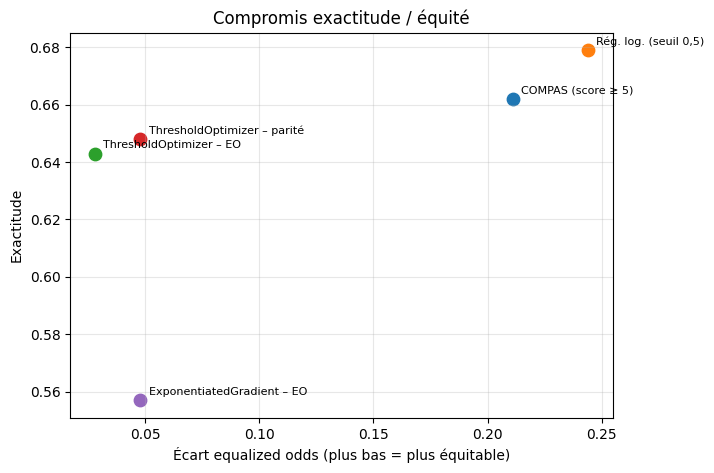

In [171]:
fig, ax = plt.subplots(figsize=(7, 5))
for nom, ligne in comparaison.iterrows():
    ax.scatter(ligne["écart EO"], ligne["exactitude"], s=80)
    ax.annotate(nom, (ligne["écart EO"], ligne["exactitude"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("Écart equalized odds (plus bas = plus équitable)")
ax.set_ylabel("Exactitude")
ax.set_title("Compromis exactitude / équité")
ax.grid(alpha=0.3)
plt.show()

In [172]:
print("Exactitude d'un modèle qui prédit toujours 'pas de récidive' :",
      round((y_test == 0).mean(), 3))

Exactitude d'un modèle qui prédit toujours 'pas de récidive' : 0.529


## 5. Correction des biais : synthèse

| Modèle | Exactitude | FPR AA / Cau | FNR AA / Cau | Précision AA / Cau | Écart EO |
|---|---|---|---|---|---|
| Rég. log. (seuil 0,5) | 67,9 % | 31,5 / 12,0 % | 34,7 / 59,1 % | 69,5 / 68,7 % | 0,244 |
| ThresholdOptimizer – EO | 64,3 % | 30,2 / 31,5 % | 42,1 / 39,3 % | 67,8 / 55,4 % | 0,028 |
| ThresholdOptimizer – parité | 64,8 % | 22,0 / 25,0 % | 50,1 / 45,3 % | 71,3 / 58,4 % | 0,048 |
| ExponentiatedGradient – EO | 55,7 % | 15,6 / 14,1 % | 75,8 / 80,6 % | 63,0 / 47,1 % | 0,048 |

- **ThresholdOptimizer** divise l'écart equalized odds par près de 9 pour 3,6 points d'exactitude.
  L'égalité est atteinte surtout en augmentant les faux positifs chez les Caucasiens (12 % → 31,5 %) :
  les erreurs sont mieux réparties, pas moins nombreuses. Il exige la race au moment de la décision
  et recourt à des décisions aléatoires près du seuil, ce qui pose des problèmes juridiques et éthiques.
- **La calibration est perdue** : l'écart de précision passe de 0,8 à 12,4 points. Égaliser les erreurs
  a détruit l'égalité de sens du score (section 6).
- **ExponentiatedGradient** atteint l'équité en classant presque tout le monde « faible risque » ;
  son exactitude (55,7 %) dépasse à peine celle d'un modèle naïf (≈ 52,9 %). Un réglage plus fin
  serait nécessaire.

In [173]:
for groupe, d in df_ab.groupby("race"):
    vn, fp, fn, vp = confusion_matrix(d["two_year_recid"], d["compas_haut_risque"]).ravel()
    p    = d["two_year_recid"].mean()
    prec = vp / (vp + fp)
    fnr  = fn / (fn + vp)
    fpr_reel    = fp / (fp + vn)
    fpr_formule = p / (1 - p) * (1 - prec) / prec * (1 - fnr)
    print(f"{groupe:<17} p={p:.3f}  précision={prec:.3f}  FNR={fnr:.3f}  "
          f"→ FPR formule={fpr_formule:.3f}  | FPR réel={fpr_reel:.3f}")

African-American  p=0.523  précision=0.650  FNR=0.285  → FPR formule=0.423  | FPR réel=0.423
Caucasian         p=0.391  précision=0.595  FNR=0.496  → FPR formule=0.220  | FPR réel=0.220


## 6. Discussion

### Le théorème d'impossibilité
Kleinberg, Mullainathan et Raghavan (2016) et Chouldechova (2017) ont montré qu'un classifieur ne peut
pas être à la fois calibré et avoir des taux de faux positifs et de faux négatifs égaux entre groupes,
sauf s'il est parfait ou si les taux de base sont égaux. La formule de Chouldechova,
FPR = p/(1−p) × (1−précision)/précision × (1−FNR), retrouve exactement les FPR de COMPAS
(0,423 et 0,220) à partir des taux de base (52,3 % et 39,1 %), de la précision et du FNR.

Nos expériences l'illustrent : sur 10 découpages, égaliser les taux d'erreur fait passer l'écart de
précision entre groupes de 0,084 à 0,138 (ThresholdOptimizer) et 0,154 (ExponentiatedGradient).
Le score perd son égalité de sens à mesure que les erreurs s'équilibrent. **ProPublica et Northpointe
avaient tous deux raison**, chacun selon sa définition de l'équité.

### Le choix d'une métrique est un choix de valeurs
Aucune correction n'est neutre. Égaliser les faux positifs protège les personnes injustement classées
« à risque » ; préserver la calibration garantit au juge qu'un score a le même sens pour tous.
Ce choix relève du droit et du débat public, pas uniquement de la technique.

### Limites
- **La cible n'est pas le délit** : `two_year_recid` mesure une nouvelle arrestation. Si un groupe est
  davantage contrôlé, son taux de base mesuré est surestimé, et toutes les métriques en héritent.
- **Le filtrage des données est contesté** : Barenstein (2019) estime que la construction du jeu de
  données a conservé trop de récidivistes (taux de 45,1 % au lieu de 36,2 % après correction).
- **Données restreintes** : un seul comté (Broward, Floride), 2013-2014 ; deux groupes seulement ;
  la race est traitée comme une catégorie administrative.
- **Robustesse** : les conclusions principales ont été vérifiées sur 10 découpages aléatoires
  (section 5 bis). Ce test a conduit à corriger une conclusion initiale sur la calibration.
- **ExponentiatedGradient** n'a pas été réglé ; ses mauvais résultats ne disent rien de la méthode
  en général.
- **Équité de groupe uniquement** : deux personnes identiques peuvent recevoir des décisions
  différentes (seuils par groupe, tirages aléatoires), ce qui pose la question de l'équité individuelle.

In [174]:
metriques_robu = {"exactitude": accuracy_score, "précision": precision_score,
                  "FPR": false_positive_rate, "FNR": false_negative_rate,
                  "taux_sélection": selection_rate}

def une_experience(seed):
    (X_tr, X_te, y_tr, y_te, A_tr, A_te, c_tr, c_te) = train_test_split(
        X, y, A, df_ab["decile_score"],
        test_size=0.3, random_state=seed, stratify=strate)


    lr = clone(logreg).fit(X_tr, y_tr)
    p = lr.predict_proba(X_te)[:, 1]


    to = ThresholdOptimizer(estimator=lr, constraints="equalized_odds",
                            objective="accuracy_score", prefit=True,
                            predict_method="predict_proba")
    to.fit(X_tr, y_tr, sensitive_features=A_tr)

  
    prep = clone(prepro).fit(X_tr)
    eg = ExponentiatedGradient(LogisticRegression(max_iter=1000),
                               constraints=EqualizedOdds())
    eg.fit(prep.transform(X_tr), y_tr, sensitive_features=A_tr)

    preds = {
        "COMPAS (score ≥ 5)":         (c_te >= 5).astype(int).to_numpy(),
        "Rég. log. (seuil 0,5)":      (p >= 0.5).astype(int),
        "ThresholdOptimizer – EO":    to.predict(X_te, sensitive_features=A_te, random_state=seed),
        "ExponentiatedGradient – EO": eg.predict(prep.transform(X_te), random_state=seed),
    }

    lignes = []
    for nom, pred in preds.items():
        mf = MetricFrame(metrics=metriques_robu, y_true=y_te, y_pred=pred,
                         sensitive_features=A_te)
        ecarts = mf.difference()
        lignes.append({
            "graine": seed, "modèle": nom,
            "exactitude": mf.overall["exactitude"],
            "écart FPR": ecarts["FPR"],
            "écart FNR": ecarts["FNR"],
            "écart EO": equalized_odds_difference(y_te, pred, sensitive_features=A_te),
            "écart parité": ecarts["taux_sélection"],
            "écart précision": ecarts["précision"],
        })

    auc = {"graine": seed,
           "AUC COMPAS": roc_auc_score(y_te, c_te),
           "AUC rég. log.": roc_auc_score(y_te, p)}
    return lignes, auc

In [175]:
toutes_lignes, aucs = [], []
for seed in range(10):
    lignes, auc = une_experience(seed)
    toutes_lignes += lignes
    aucs.append(auc)
    print(f"graine {seed} terminée")

res = pd.DataFrame(toutes_lignes)
res_auc = pd.DataFrame(aucs)

graine 0 terminée
graine 1 terminée
graine 2 terminée
graine 3 terminée
graine 4 terminée
graine 5 terminée
graine 6 terminée
graine 7 terminée
graine 8 terminée
graine 9 terminée


In [176]:
ordre = ["COMPAS (score ≥ 5)", "Rég. log. (seuil 0,5)",
         "ThresholdOptimizer – EO", "ExponentiatedGradient – EO"]
cols = ["exactitude", "écart FPR", "écart FNR", "écart EO", "écart parité", "écart précision"]

moy = res.groupby("modèle")[cols].mean().reindex(ordre)
et  = res.groupby("modèle")[cols].std().reindex(ordre)
tableau_robu = moy.map(lambda v: f"{v:.3f}") + " ± " + et.map(lambda v: f"{v:.3f}")
tableau_robu

,exactitude,écart FPR,écart FNR,écart EO,écart parité,écart précision
modèle,,,,,,
COMPAS (score ≥ 5),0.658 ± 0.007,0.198 ± 0.029,0.199 ± 0.028,0.213 ± 0.026,0.237 ± 0.022,0.054 ± 0.028
"Rég. log. (seuil 0,5)",0.676 ± 0.008,0.149 ± 0.032,0.259 ± 0.025,0.259 ± 0.025,0.240 ± 0.021,0.084 ± 0.032
ThresholdOptimizer – EO,0.637 ± 0.011,0.033 ± 0.018,0.033 ± 0.021,0.041 ± 0.019,0.033 ± 0.020,0.138 ± 0.034
ExponentiatedGradient – EO,0.540 ± 0.016,0.017 ± 0.014,0.029 ± 0.016,0.033 ± 0.013,0.018 ± 0.015,0.154 ± 0.045


In [177]:
res_auc["différence"] = res_auc["AUC rég. log."] - res_auc["AUC COMPAS"]
print(res_auc.round(3).to_string(index=False))
print(f"\nAUC COMPAS     : {res_auc['AUC COMPAS'].mean():.3f} ± {res_auc['AUC COMPAS'].std():.3f}")
print(f"AUC rég. log.  : {res_auc['AUC rég. log.'].mean():.3f} ± {res_auc['AUC rég. log.'].std():.3f}")
print(f"Rég. log. meilleure dans {(res_auc['différence'] > 0).sum()} tirages sur 10")

 graine  AUC COMPAS  AUC rég. log.  différence
      0       0.720          0.719      -0.001
      1       0.719          0.723       0.004
      2       0.717          0.745       0.028
      3       0.725          0.718      -0.007
      4       0.707          0.721       0.014
      5       0.696          0.733       0.037
      6       0.702          0.725       0.023
      7       0.727          0.725      -0.002
      8       0.708          0.730       0.021
      9       0.711          0.735       0.024

AUC COMPAS     : 0.713 ± 0.010
AUC rég. log.  : 0.727 ± 0.008
Rég. log. meilleure dans 7 tirages sur 10


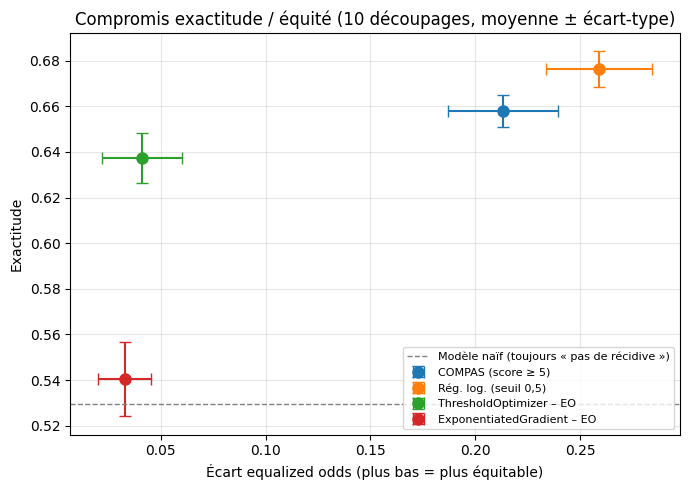

In [178]:
fig, ax = plt.subplots(figsize=(7, 5))
for nom in ordre:
    ax.errorbar(moy.loc[nom, "écart EO"], moy.loc[nom, "exactitude"],
                xerr=et.loc[nom, "écart EO"], yerr=et.loc[nom, "exactitude"],
                fmt="o", capsize=4, markersize=8, label=nom)
ax.axhline((y == 0).mean(), ls="--", color="grey", lw=1,
           label="Modèle naïf (toujours « pas de récidive »)")
ax.set_xlabel("Écart equalized odds (plus bas = plus équitable)")
ax.set_ylabel("Exactitude")
ax.set_title("Compromis exactitude / équité (10 découpages, moyenne ± écart-type)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
import os; os.makedirs("figures", exist_ok=True)
fig.savefig("figures/compromis_exactitude_equite.png", dpi=150, bbox_inches="tight")